# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [13]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 16                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = True      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 16 — Аренда спецтехники
Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести
аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»

CSV  : Парки техники        (справочник субъектов)
XLSX : Смены аренды          (события, объём в единицах: машино-часов)
JSON : Ставки аренды          (цены, разрез: тип техники)

Объём генерации: субъектов 9, событий 5 000, уровень дефектов ★★
Аналитическая задача: Утилизация парка и доходность типов техники


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    5 000   размер:    183.1 КБ
prices.json     строк:   10 067   размер:   1263.6 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for col in df.columns:
        s = df[col]
        # пустая строка и строка из пробелов — тоже пропуск
        filled = s.notna() & (s.astype("string").str.strip() != "")
        # для JSON показываем реальные python-типы значений: там цена бывает и числом, и строкой
        py_types = sorted({type(v).__name__ for v in s.dropna()})
        examples = s[filled].drop_duplicates().head(2).tolist()
        rows.append({
            "источник": name,
            "колонка": col,
            "тип pandas": str(s.dtype),
            "типы значений": ", ".join(py_types),
            "строк": len(s),
            "заполнено, %": round(100 * filled.mean(), 2),
            "пропусков": int((~filled).sum()),
            "уникальных": int(s[filled].astype(str).nunique()),
            "пример 1": examples[0] if len(examples) > 0 else None,
            "пример 2": examples[1] if len(examples) > 1 else None,
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

SRC_E, SRC_V, SRC_P = list(SOURCES.keys())

def _quick_num(s):
    """Черновой разбор числа только для аудита (полноценный разбор — TODO 4.1)."""
    t = s.astype("string").str.replace(r"[^\d,.\-]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(t, errors="coerce")

def _blank(s):
    return s.isna() | (s.astype("string").str.strip() == "")

# --- 1. Полнота -------------------------------------------------------------------
for src, df in SOURCES.items():
    for col in df.columns:
        n_miss = int(_blank(df[col]).sum())
        if n_miss:
            action = {"region": "оставить пропуском (NULL), не подставлять значение",
                      "volume_units": "оставить NULL: событие сохраняется, в выручку не входит",
                      "unit_price": "строку цены — в карантин quarantine_price (цена неизвестна)"
                      }.get(col, "оставить пропуском")
            add_issue("Полнота", src, f"пропуски в колонке {col}", n_miss, action)

# --- 2. Уникальность --------------------------------------------------------------
for src, df, key in [(SRC_E, raw_entities, "entity_id"), (SRC_V, raw_events, "event_id"),
                     (SRC_P, raw_prices, "price_id")]:
    n_full = int(df.astype(str).duplicated().sum())
    n_key = int(df[key].duplicated().sum())
    add_issue("Уникальность", src, "полные дубликаты строк", n_full,
              "удалить повтор, оставить первую запись (журнал)" if n_full else "проблемы нет — контроль пройден")
    add_issue("Уникальность", src, f"повторы ключа {key}", n_key,
              "дедупликация по ключу, keep='first' (журнал)" if n_key else "проблемы нет — контроль пройден")

# --- 3. Согласованность -----------------------------------------------------------
d = raw_events["event_date"].astype("string").str.strip()
n_iso = int(d.str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum())
n_ru = int(d.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum())
add_issue("Согласованность", SRC_V, "дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД", n_ru,
          "явный разбор обоих форматов, хранение в ISO 8601")
add_issue("Согласованность", SRC_V, "дата не распознана ни в одном формате",
          int(d.notna().sum()) - n_iso - n_ru, "в карантин (дата обязательна)")
vol = raw_events["volume_units"].astype("string")
add_issue("Согласованность", SRC_V, "объём записан текстом с пробелами ('123 ')",
          int((vol.notna() & ~vol.str.fullmatch(r"\d+")).sum()), "очистка пробелов, явное приведение к числу")
pr_is_str = raw_prices["unit_price"].map(lambda v: isinstance(v, str))
add_issue("Согласованность", SRC_P, "цена строкой с валютой и пробелом-разделителем ('4 512.30 ₽')",
          int(pr_is_str.sum()), "разбор to_number(): удалить ₽ и пробелы, привести к float")
name = raw_entities["entity_name"].astype("string")
bad_name = (name != name.str.strip()) | (name == name.str.upper())
add_issue("Согласованность", SRC_E, "название субъекта с лишними пробелами / в ВЕРХНЕМ регистре",
          int(bad_name.sum()), "strip + приведение регистра к эталону справочника")

# --- 4. Валидность ----------------------------------------------------------------
p_num = _quick_num(raw_prices["unit_price"])
v_num = _quick_num(raw_events["volume_units"])
add_issue("Валидность", SRC_P, "отрицательная или нулевая цена", int((p_num <= 0).sum()),
          "в карантин quarantine_price; знак не «исправляем» abs() — причина неизвестна")
add_issue("Валидность", SRC_V, "нулевой или отрицательный объём", int((v_num <= 0).sum()),
          "в карантин" if (v_num <= 0).any() else "проблемы нет — контроль пройден")
fy = pd.to_numeric(raw_entities["founded_year"], errors="coerce")
add_issue("Валидность", SRC_E, "год основания вне диапазона 1900–2026",
          int(((fy < 1900) | (fy > 2026)).sum()), "проблемы нет — контроль пройден")

# --- 5. Целостность (в обе стороны) -----------------------------------------------
ent_ids = set(raw_entities["entity_id"])
ev_ids = set(raw_events["event_id"])
orphan_ev = ~raw_events["entity_id"].isin(ent_ids)
add_issue("Целостность", SRC_V, "entity_id отсутствует в справочнике (сироты, напр. "
          + ", ".join(sorted(raw_events.loc[orphan_ev, "entity_id"].unique())) + ")",
          int(orphan_ev.sum()), "события и их цены — в карантин quarantine_fk")
add_issue("Целостность", SRC_P, "event_id отсутствует в событиях",
          int((~raw_prices["event_id"].isin(ev_ids)).sum()), "в карантин quarantine_fk")
add_issue("Целостность", SRC_P, "цены событий-сирот (родитель уйдёт в карантин)",
          int(raw_prices["event_id"].isin(set(raw_events.loc[orphan_ev, "event_id"])).sum()),
          "в карантин quarantine_fk вместе с событием")
add_issue("Целостность", SRC_E, "субъект справочника без единого события",
          int((~raw_entities["entity_id"].drop_duplicates().isin(set(raw_events["entity_id"]))).sum()),
          "сохранить в справочнике, выручка 0 не выдумывается — отражается отсутствием")
add_issue("Целостность", SRC_V, "событие без единой ценовой строки",
          int((~raw_events["event_id"].isin(set(raw_prices["event_id"]))).sum()),
          "событие сохраняется, в выручку не входит")

# --- 6. Точность: выбросы 3×IQR ---------------------------------------------------
def iqr_outliers(x, k=3.0):
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    return (x < q1 - k * iqr) | (x > q3 + k * iqr), (q1 - k * iqr, q3 + k * iqr)

p_ok = p_num[p_num > 0]
out_all, (lo, hi) = iqr_outliers(p_ok)
add_issue("Точность", SRC_P, f"выбросы цены по 3×IQR по всей таблице (границы {nf(lo)}…{nf(hi)} ₽)",
          int(out_all.sum()), "сигнал для проверки, строки не удаляются")
cls_out = 0
for kl, grp in pd.DataFrame({"p": p_ok, "c": raw_prices.loc[p_ok.index, "price_class"]}).groupby("c"):
    cls_out += int(iqr_outliers(grp["p"])[0].sum())
add_issue("Точность", SRC_P, f"выбросы цены по 3×IQR внутри класса ({CFG['cls']})", cls_out,
          "сигнал: сверить ставку с прайсом класса; не удалять автоматически")
# ставки, пришедшие строкой с «₽», сверяем с диапазоном числовых ставок того же класса
_pc = pd.DataFrame({"p": p_num, "c": raw_prices["price_class"], "txt": pr_is_str})
_rng = _pc[~_pc["txt"] & (_pc["p"] > 0)].groupby("c")["p"].agg(["min", "max"])
_t = _pc[_pc["txt"]].join(_rng, on="c")
_susp = (_t["p"] < _t["min"]) | (_t["p"] > _t["max"])
add_issue("Точность", SRC_P, "ставка строкой с «₽» вне диапазона числовых ставок своего класса", int(_susp.sum()),
          "сигнал: вероятно, ставка указана без коэффициента класса; запросить у владельца, не удалять")
v_ok = v_num[v_num > 0]
add_issue("Точность", SRC_V, "выбросы объёма по 3×IQR", int(iqr_outliers(v_ok)[0].sum()),
          "сигнал для проверки, строки не удаляются")

issues_df = pd.DataFrame(issues)
found = issues_df[issues_df["строк"] > 0]
print(f"Проверок выполнено: {len(issues_df)}; найдено проблем (строк > 0): {len(found)} "
      f"по измерениям: {', '.join(found['измерение'].unique())}")
display(issues_df)

# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?
ev_per_ent = raw_events.groupby("entity_id").size()
pr_per_ev = raw_prices.groupby("event_id").size().reindex(raw_events["event_id"].unique(), fill_value=0)
ent_per_id = raw_entities.groupby("entity_id").size()
card = pd.DataFrame([
    {"связь": f"entities → events ({CFG['parent']} → {CFG['event']})", "тип": "1 : N",
     "мин": ev_per_ent.min(), "среднее": ev_per_ent.mean(), "медиана": ev_per_ent.median(), "макс": ev_per_ent.max()},
    {"связь": f"events → prices ({CFG['event']} → {CFG['price']})", "тип": "1 : N",
     "мин": pr_per_ev.min(), "среднее": pr_per_ev.mean(), "медиана": pr_per_ev.median(), "макс": pr_per_ev.max()},
    {"связь": "entity_id в справочнике (ожидается 1 : 1)", "тип": "1 : 1?",
     "мин": ent_per_id.min(), "среднее": ent_per_id.mean(), "медиана": ent_per_id.median(), "макс": ent_per_id.max()},
])
display(card)
print("Распределение числа ценовых строк на событие:")
print(pr_per_ev.value_counts().sort_index().rename("событий").to_string())

# ожидаемое завышение: вес каждого события в наивной сумме = число его ценовых строк
_v = v_num.groupby(raw_events["event_id"]).first()
expected_vol_factor = (_v * pr_per_ev.reindex(_v.index)).sum() / _v[pr_per_ev.reindex(_v.index) > 0].sum()
dup_ent = int(ent_per_id.max())
print(f"\nОтвет. Связь events → prices — один-ко-многим: в среднем {pr_per_ev.mean():.2f} ценовые строки "
      f"на событие (максимум {pr_per_ev.max()}). При наивном JOIN трёх таблиц строка события повторится "
      f"столько раз, сколько у него цен, поэтому SUM(volume_units) вырастет примерно в {expected_vol_factor:.2f} раза, "
      f"а SUM(volume_units * unit_price) будет суммой по всем строкам цен вместо средней цены события — выручка "
      f"завысится примерно во столько же раз. Дополнительно в справочнике entity_id повторяется до {dup_ent} раз: "
      f"без дедупликации JOIN с entities удвоит события этого субъекта ещё раз.")

,источник,колонка,тип pandas,типы значений,строк,"заполнено, %",пропусков,уникальных,пример 1,пример 2
0,CSV · Парки техники,entity_id,object,str,10,100.00,0,9,E001,E002
1,CSV · Парки техники,entity_name,object,str,10,100.00,0,9,Парки техники «Пермь»,Парки техники «Москва»
2,CSV · Парки техники,region,object,str,10,90.00,1,8,Пермь,Москва
3,CSV · Парки техники,founded_year,object,str,10,100.00,0,7,1992,2006
4,XLSX · Смены аренды,event_id,object,str,5000,100.00,0,5000,EV000001,EV000002
5,XLSX · Смены аренды,entity_id,object,str,5000,100.00,0,10,E001,E003
6,XLSX · Смены аренды,event_date,object,str,5000,100.00,0,381,2025-06-15,2025-02-17
7,XLSX · Смены аренды,route,object,str,5000,100.00,0,144,Ростов-на-Дону — Самара,Уфа — Тюмень
8,XLSX · Смены аренды,volume_units,object,str,5000,99.68,16,392,380,288
9,XLSX · Смены аренды,asset_type,object,str,5000,100.00,0,4,Тип B,Тип A


Проверок выполнено: 26; найдено проблем (строк > 0): 13 по измерениям: Полнота, Уникальность, Согласованность, Валидность, Целостность, Точность


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Парки техники,пропуски в колонке region,1,"оставить пропуском (NULL), не подставлять знач..."
1,Полнота,XLSX · Смены аренды,пропуски в колонке volume_units,16,"оставить NULL: событие сохраняется, в выручку ..."
2,Полнота,JSON · Ставки аренды,пропуски в колонке unit_price,22,строку цены — в карантин quarantine_price (цен...
3,Уникальность,CSV · Парки техники,полные дубликаты строк,1,"удалить повтор, оставить первую запись (журнал)"
4,Уникальность,CSV · Парки техники,повторы ключа entity_id,1,"дедупликация по ключу, keep='first' (журнал)"
5,Уникальность,XLSX · Смены аренды,полные дубликаты строк,0,проблемы нет — контроль пройден
6,Уникальность,XLSX · Смены аренды,повторы ключа event_id,0,проблемы нет — контроль пройден
7,Уникальность,JSON · Ставки аренды,полные дубликаты строк,0,проблемы нет — контроль пройден
8,Уникальность,JSON · Ставки аренды,повторы ключа price_id,0,проблемы нет — контроль пройден
9,Согласованность,XLSX · Смены аренды,дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД,16,"явный разбор обоих форматов, хранение в ISO 8601"


,связь,тип,мин,среднее,медиана,макс
0,entities → events (Парки техники → Смены аренды),1 : N,25,500.00,488.00,925
1,events → prices (Смены аренды → Ставки аренды),1 : N,1,2.01,2.00,3
2,entity_id в справочнике (ожидается 1 : 1),1 : 1?,1,1.11,1.00,2


Распределение числа ценовых строк на событие:
1    1635
2    1663
3    1702

Ответ. Связь events → prices — один-ко-многим: в среднем 2.01 ценовые строки на событие (максимум 3). При наивном JOIN трёх таблиц строка события повторится столько раз, сколько у него цен, поэтому SUM(volume_units) вырастет примерно в 2.01 раза, а SUM(volume_units * unit_price) будет суммой по всем строкам цен вместо средней цены события — выручка завысится примерно во столько же раз. Дополнительно в справочнике entity_id повторяется до 2 раз: без дедупликации JOIN с entities удвоит события этого субъекта ещё раз.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

**Выводы по шагу 3 (вариант 16).**

* Профиль: все колонки CSV и XLSX прочитаны как текст (`dtype=str`), ведущие нули в ключах `E001`, `EV000001`, `PR0000001` сохранены. В JSON колонка `unit_price` смешанного типа (`float` и `str`) — это и есть дефект согласованности, который нельзя увидеть, если позволить pandas привести тип.
* Журнал: 26 проверок, проблемы найдены в **13** из них, по всем **шести** измерениям: пропуски (`region` — 1, `volume_units` — 16, `unit_price` — 22), дубль строки справочника (1), 16 дат в формате `ДД.ММ.ГГГГ`, 18 объёмов текстом с пробелом, 22 ставки строкой с «₽», 1 название в верхнем регистре с пробелами, 23 отрицательные ставки, 25 смен парка-«сироты» `E999` и 47 их ставок, 10 текстовых ставок вне диапазона своего типа техники.
* Выбросов по правилу 3×IQR нет ни в ценах, ни в объёмах: распределения ограничены генератором. Отсутствие выбросов не доказывает точность — содержательная проверка (сверка ставки с диапазоном класса) нашла 10 подозрительных значений.
* Кардинальность: `entities → events` — 1 : N (от 25 до 925 смен на парк, считая сироту), `events → prices` — 1 : N (в среднем **2,01** ставки на смену, максимум 3). Кроме того, ключ `entity_id` в сыром справочнике не уникален (дубль `E002`). Наивный JOIN завысит объём и выручку примерно в 2 раза.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment, affected=None):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after,
                      "затронуто строк": (before - after) if affected is None else affected,
                      "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    def parse_one(v):
        if v is None or (isinstance(v, float) and math.isnan(v)):
            return None                                   # пропуск остаётся пропуском
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        s = re.sub(r"[^\d,.\-]", "", str(v))              # ₽, обычные и неразрывные пробелы и пр.
        if s in ("", "-", ".", ","):
            return None
        if "," in s and "." in s:                          # '1,234.50' или '1.234,50'
            if s.rfind(",") > s.rfind("."):                # последней стоит запятая → она десятичная
                s = s.replace(".", "").replace(",", ".")
            else:
                s = s.replace(",", "")
        elif "," in s:
            # '8,500' или '1,234,567' → разделитель разрядов; '8500,00' или '12,5' → десятичная
            if re.fullmatch(r"-?\d{1,3}(,\d{3})+", s):
                s = s.replace(",", "")
            else:
                head, _, tail = s.rpartition(",")
                s = head.replace(",", "") + "." + tail
        return s
    return pd.to_numeric(series.map(parse_one).astype("object"), errors="coerce").astype("float64")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype("string").str.strip().str.slice(0, 10)   # отрезаем возможное '00:00:00'
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# самопроверка парсеров на примерах из подсказки
_t = to_number(pd.Series(["8 500,00 ₽", "180 ", None, "4 512.30 ₽", "-1234.5", "1,234.50", "8,500"]))
assert _t.iloc[0] == 8500.0 and _t.iloc[1] == 180.0 and pd.isna(_t.iloc[2]) and _t.iloc[3] == 4512.30
assert _t.iloc[4] == -1234.5 and _t.iloc[5] == 1234.5 and _t.iloc[6] == 8500.0
_d = to_date(pd.Series(["2025-03-17", "17.03.2025", "2025/03/17", None]))
assert _d.iloc[0] == _d.iloc[1] == pd.Timestamp("2025-03-17") and _d.iloc[2:].isna().all()
print("Парсеры to_number и to_date прошли контрольные примеры")

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.

# Исходные raw_* не изменяются: работаем с копиями (требование «сохраните исходные данные»)
removed_dups = []                       # удалённые дубли тоже сохраняем — для полноты аудита

# ---------- 4.3.1 Справочник ----------------------------------------------------------
entities = raw_entities.copy()
n0 = len(entities)
dup_mask = entities.duplicated(subset="entity_id", keep="first")
removed_dups.append(entities[dup_mask].assign(source="entities", reason="дубликат entity_id"))
entities = entities[~dup_mask].reset_index(drop=True)
log_step("4.3.1 entities: дедупликация по entity_id", n0, len(entities),
         "полный дубль строки справочника, оставлена первая запись")

def normalize_name(name, region):
    """Убираем лишние пробелы; название в ВЕРХНЕМ регистре приводим к эталонному виду
    «<Тип субъекта> «<Город>»», где город берём из справочного списка городов генератора."""
    if pd.isna(name):
        return name
    s = re.sub(r"\s+", " ", str(name)).strip()
    if s == s.upper():
        m = re.match(r"^(.*?)\s*«(.*)»$", s)
        if m:
            head = m.group(1).capitalize()
            city_up = m.group(2)
            city = next((c for c in KNOWN_CITIES if c.upper() == city_up), city_up.title())
            s = f"{head} «{city}»"
        else:
            s = s.capitalize()
    return s

KNOWN_CITIES = sorted(set(raw_entities["region"].dropna()) |
                      {"Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань", "Краснодар",
                       "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"})
before_names = entities["entity_name"].copy()
entities["entity_name"] = [normalize_name(nm, rg) for nm, rg in zip(entities["entity_name"], entities["region"])]
name_changes = pd.DataFrame({"entity_id": entities["entity_id"], "было": before_names,
                             "стало": entities["entity_name"]})[before_names != entities["entity_name"]]
log_step("4.3.2 entities: нормализация названий", len(entities), len(entities),
         "strip/схлопывание пробелов, ВЕРХНИЙ регистр → эталонный вид: " +
         "; ".join(f"{r.entity_id}: '{r.было}' → '{r.стало}'" for r in name_changes.itertuples()),
         affected=len(name_changes))
entities["region"] = entities["region"].astype("string").str.strip()
entities["founded_year"] = to_number(entities["founded_year"]).astype("Int64")
log_step("4.3.3 entities: типы", len(entities), len(entities),
         f"founded_year → целое; пропуски region оставлены пропусками "
         f"({int(entities['region'].isna().sum())} шт., значение не подставлялось)", affected=0)

# ---------- 4.3.2 События --------------------------------------------------------------
events = raw_events.copy()
n0 = len(events)
dup_mask = events.duplicated(subset="event_id", keep="first")
removed_dups.append(events[dup_mask].assign(source="events", reason="дубликат event_id"))
events = events[~dup_mask].reset_index(drop=True)
log_step("4.3.4 events: дедупликация по event_id", n0, len(events),
         "повторов event_id нет (уровень дефектов ★★)" if n0 == len(events) else "оставлена первая запись")

raw_date = events["event_date"].copy()
events["event_date"] = to_date(events["event_date"])
n_ru_fmt = int(raw_date.astype("string").str.fullmatch(r"\d{2}\.\d{2}\.\d{4}").sum())
log_step("4.3.5 events: разбор дат", len(events), len(events),
         f"два формата → datetime; ДД.ММ.ГГГГ распознано: {n_ru_fmt}; NaT: {int(events['event_date'].isna().sum())}",
         affected=n_ru_fmt)

raw_vol = events["volume_units"].copy()
events["volume_units"] = to_number(events["volume_units"])
n_txt = int((raw_vol.notna() & ~raw_vol.astype("string").str.fullmatch(r"\d+")).sum())
log_step("4.3.6 events: разбор объёма", len(events), len(events),
         f"текст с пробелами → число: {n_txt}; пропусков осталось пропусками: "
         f"{int(events['volume_units'].isna().sum())} (не заменены нулём)", affected=n_txt)
events["entity_id"] = events["entity_id"].astype("string").str.strip()

# карантин по целостности: entity_id отсутствует в справочнике
fk_bad = ~events["entity_id"].isin(set(entities["entity_id"]))
q_ev_fk = events[fk_bad].assign(source="events", reason="entity_id отсутствует в справочнике entities")
events = events[~fk_bad]
log_step("4.3.7 events: ссылочная целостность → quarantine_fk", len(events) + len(q_ev_fk), len(events),
         f"события с entity_id ∉ entities ({', '.join(sorted(q_ev_fk['entity_id'].unique()))}) — в карантин")

# карантин по значениям: нераспознанная дата или объём ≤ 0 (пропуск объёма НЕ карантин — это NULL)
bad_val = events["event_date"].isna() | (events["volume_units"] <= 0)
q_ev_val = events[bad_val].assign(source="events", reason="нераспознанная дата или объём ≤ 0")
events_valid = events[~bad_val].reset_index(drop=True)
log_step("4.3.8 events: допустимость значений → quarantine_price", len(events), len(events_valid),
         "дата не распознана или объём ≤ 0" + (" — таких строк нет" if len(q_ev_val) == 0 else ""))

# ---------- 4.3.3 Цены -----------------------------------------------------------------
prices = raw_prices.copy()
n0 = len(prices)
dup_mask = prices.duplicated(subset="price_id", keep="first")
removed_dups.append(prices[dup_mask].assign(source="prices", reason="дубликат price_id"))
prices = prices[~dup_mask].reset_index(drop=True)
log_step("4.3.9 prices: дедупликация по price_id", n0, len(prices),
         "повторов price_id нет (уровень дефектов ★★)" if n0 == len(prices) else "оставлена первая запись")

prices["unit_price_raw"] = prices["unit_price"].astype("string")       # исходное значение сохраняем
is_text = prices["unit_price"].map(lambda v: isinstance(v, str))
prices["unit_price"] = to_number(prices["unit_price"])
log_step("4.3.10 prices: разбор цен", len(prices), len(prices),
         f"строки с ₽ и пробелами → число: {int(is_text.sum())}; пропуски остались NaN: "
         f"{int(prices['unit_price'].isna().sum())}", affected=int(is_text.sum()))

# целостность: цены событий, которых нет среди событий (в т.ч. событий, ушедших в карантин)
fk_bad = ~prices["event_id"].isin(set(events_valid["event_id"]))
q_pr_fk = prices[fk_bad].assign(source="prices", reason=np.where(
    prices.loc[fk_bad, "event_id"].isin(set(q_ev_fk["event_id"])),
    "цена события из карантина (entity_id ∉ entities)", "event_id отсутствует в events"))
prices = prices[~fk_bad]
log_step("4.3.11 prices: ссылочная целостность → quarantine_fk", len(prices) + len(q_pr_fk), len(prices),
         "цены, чьё событие отсутствует или ушло в карантин")

# допустимость: пропуск цены и цена ≤ 0
miss = prices["unit_price"].isna()
neg = prices["unit_price"] <= 0
q_pr_val = pd.concat([prices[miss].assign(source="prices", reason="пропуск цены (NaN сохранён)"),
                      prices[neg].assign(source="prices", reason="цена ≤ 0")])
prices_valid = prices[~(miss | neg)].reset_index(drop=True)
log_step("4.3.12 prices: пропуски цен → quarantine_price", len(prices), len(prices) - int(miss.sum()),
         "строка цены без значения непригодна для расчёта; в карантине NaN остаётся NaN")
log_step("4.3.13 prices: отрицательные цены → quarantine_price", len(prices) - int(miss.sum()), len(prices_valid),
         "цена ≤ 0 нарушает правило валидности; abs() не применяется")

# ---------- 4.3.4 Итоговые наборы ------------------------------------------------------
quarantine_fk = pd.concat([q_ev_fk, q_pr_fk], ignore_index=True)
quarantine_price = pd.concat([q_ev_val, q_pr_val], ignore_index=True)
removed_dups = pd.concat(removed_dups, ignore_index=True)

ev_without_price = ~events_valid["event_id"].isin(set(prices_valid["event_id"]))
log_step("4.3.14 events: события без валидной цены (информационно)", len(events_valid), len(events_valid),
         f"остаются в events, но в выручку не попадут: {int(ev_without_price.sum())} событий; "
         f"событий без объёма (NULL): {int(events_valid['volume_units'].isna().sum())}",
         affected=int(ev_without_price.sum()))

clean_log = pd.DataFrame(CLEAN_LOG)
display(clean_log)

# баланс строк: ни одна строка не исчезла бесследно
balance = pd.DataFrame([
    {"набор": "entities", "исходно": len(raw_entities), "очищено": len(entities),
     "дубли": int((removed_dups["source"] == "entities").sum()), "карантин": 0},
    {"набор": "events", "исходно": len(raw_events), "очищено": len(events_valid),
     "дубли": int((removed_dups["source"] == "events").sum()),
     "карантин": int((quarantine_fk["source"] == "events").sum() + (quarantine_price["source"] == "events").sum())},
    {"набор": "prices", "исходно": len(raw_prices), "очищено": len(prices_valid),
     "дубли": int((removed_dups["source"] == "prices").sum()),
     "карантин": int((quarantine_fk["source"] == "prices").sum() + (quarantine_price["source"] == "prices").sum())},
])
balance["сходится"] = balance["исходно"] == balance["очищено"] + balance["дубли"] + balance["карантин"]
balance["доля потерь, %"] = 100 * (balance["дубли"] + balance["карантин"]) / balance["исходно"]
display(balance)
assert balance["сходится"].all(), "строки потеряны без журнала"

print(f"quarantine_fk: {len(quarantine_fk)} строк | quarantine_price: {len(quarantine_price)} строк")
display(pd.concat([quarantine_fk, quarantine_price]).groupby(["source", "reason"]).size().rename("строк").to_frame())
print("Примеры карантина цен:")
display(quarantine_price[["price_id", "event_id", "unit_price_raw", "unit_price", "reason"]].head(6))

# сохраняем карантин и журнал рядом с базой — материал для владельцев источников
quarantine_fk.to_csv(WORK / "quarantine_fk.csv", index=False, encoding="utf-8-sig")
quarantine_price.to_csv(WORK / "quarantine_price.csv", index=False, encoding="utf-8-sig")
clean_log.to_csv(WORK / "clean_log.csv", index=False, encoding="utf-8-sig")

Парсеры to_number и to_date прошли контрольные примеры


,шаг,было строк,стало строк,изменено,затронуто строк,комментарий
0,4.3.1 entities: дедупликация по entity_id,10,9,1,1,"полный дубль строки справочника, оставлена пер..."
1,4.3.2 entities: нормализация названий,9,9,0,1,"strip/схлопывание пробелов, ВЕРХНИЙ регистр → ..."
2,4.3.3 entities: типы,9,9,0,0,founded_year → целое; пропуски region оставлен...
3,4.3.4 events: дедупликация по event_id,5000,5000,0,0,повторов event_id нет (уровень дефектов ★★)
4,4.3.5 events: разбор дат,5000,5000,0,16,два формата → datetime; ДД.ММ.ГГГГ распознано:...
5,4.3.6 events: разбор объёма,5000,5000,0,18,текст с пробелами → число: 18; пропусков остал...
6,4.3.7 events: ссылочная целостность → quaranti...,5000,4975,25,25,события с entity_id ∉ entities (E999) — в кара...
7,4.3.8 events: допустимость значений → quaranti...,4975,4975,0,0,дата не распознана или объём ≤ 0 — таких строк...
8,4.3.9 prices: дедупликация по price_id,10067,10067,0,0,повторов price_id нет (уровень дефектов ★★)
9,4.3.10 prices: разбор цен,10067,10067,0,22,строки с ₽ и пробелами → число: 22; пропуски о...


,набор,исходно,очищено,дубли,карантин,сходится,"доля потерь, %"
0,entities,10,9,1,0,True,10.00
1,events,5000,4975,0,25,True,0.50
2,prices,10067,9977,0,90,True,0.89


quarantine_fk: 72 строк | quarantine_price: 43 строк


строк
source reason                                                 
events entity_id отсутствует в справочнике entities         25
prices пропуск цены (NaN сохранён)                          21
       цена события из карантина (entity_id ∉ entities)     47
       цена ≤ 0                                             22

Примеры карантина цен:


,price_id,event_id,unit_price_raw,unit_price,reason
0,PR0000575,EV000288,<NA>,NaN,пропуск цены (NaN сохранён)
1,PR0001303,EV000655,<NA>,NaN,пропуск цены (NaN сохранён)
2,PR0001402,EV000706,<NA>,NaN,пропуск цены (NaN сохранён)
3,PR0002394,EV001203,<NA>,NaN,пропуск цены (NaN сохранён)
4,PR0003688,EV001830,<NA>,NaN,пропуск цены (NaN сохранён)
5,PR0003749,EV001863,<NA>,NaN,пропуск цены (NaN сохранён)


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

**Выводы по шагу 4.** Баланс строк сходится по каждому набору: *исходно = очищено + дубли + карантин*. Ни одна строка не удалена без записи в журнале.

* Справочник: удалён 1 полный дубль (`E002`), название `E003` («  ПАРКИ ТЕХНИКИ «ТЮМЕНЬ» ») приведено к виду «Парки техники «Тюмень»»; пропуск региона у `E004` (Новосибирск) оставлен пропуском.
* События: обе формы даты разобраны (NaT = 0), 18 текстовых объёмов приведены к числу, 16 пропусков объёма остались `NaN`. 25 смен с `entity_id = E999` — в `quarantine_fk` (0,5 % событий).
* Ставки: 22 строки с «₽» разобраны, 47 ставок смен-сирот — в `quarantine_fk`, 21 пустая и 22 отрицательные ставки — в `quarantine_price` (0,9 % ставок). Отрицательные значения не «исправлялись» через `abs()`: причина ошибки неизвестна.
* Потери меньше порога 5 %, поэтому данные пригодны для расчёта, но карантин (файлы `quarantine_*.csv`) передаётся владельцам источников.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")
print("PRAGMA foreign_keys =", conn.execute("PRAGMA foreign_keys;").fetchone()[0])

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.
SCHEMA_SQL = """
CREATE TABLE entities (
    entity_id     TEXT PRIMARY KEY CHECK (entity_id GLOB 'E[0-9][0-9][0-9]'),
    entity_name   TEXT NOT NULL CHECK (entity_name = trim(entity_name) AND length(entity_name) > 0),
    region        TEXT,                                           -- пропуск допустим: NULL, не ''
    founded_year  INTEGER CHECK (founded_year IS NULL OR founded_year BETWEEN 1900 AND 2026)
);

CREATE TABLE events (
    event_id      TEXT PRIMARY KEY,
    entity_id     TEXT NOT NULL REFERENCES entities(entity_id) ON UPDATE CASCADE ON DELETE RESTRICT,
    event_date    TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-1][0-9]-[0-3][0-9]'),
    route         TEXT,
    volume_units  REAL CHECK (volume_units IS NULL OR volume_units > 0),  -- NULL = объём неизвестен
    asset_type    TEXT
);

CREATE TABLE prices (
    price_id      TEXT PRIMARY KEY,
    event_id      TEXT NOT NULL REFERENCES events(event_id) ON UPDATE CASCADE ON DELETE CASCADE,
    unit_price    REAL NOT NULL CHECK (unit_price > 0),
    price_class   TEXT NOT NULL
);

CREATE INDEX ix_events_entity ON events(entity_id);
CREATE INDEX ix_events_date   ON events(event_date);
CREATE INDEX ix_prices_event  ON prices(event_id);
CREATE INDEX ix_prices_class  ON prices(price_class);
"""
conn.executescript(SCHEMA_SQL)
conn.execute("PRAGMA foreign_keys = ON;")       # executescript делает COMMIT; флаг подтверждаем повторно
display(pd.read_sql("SELECT type, name, tbl_name FROM sqlite_master WHERE name NOT LIKE 'sqlite_%' "
                    "ORDER BY type DESC, name", conn))

# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.
entities_out = entities[["entity_id", "entity_name", "region", "founded_year"]].copy()
events_out = events_valid[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")      # ISO-текст для SQLite
prices_out = prices_valid[["price_id", "event_id", "unit_price", "price_class"]].copy()

# if_exists="append" — сохраняем нашу схему с ключами (replace пересоздал бы таблицу без ограничений)
entities_out.to_sql("entities", conn, if_exists="append", index=False)
events_out.to_sql("events", conn, if_exists="append", index=False)
prices_out.to_sql("prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк_в_БД FROM entities UNION ALL
    SELECT 'events',   COUNT(*) FROM events   UNION ALL
    SELECT 'prices',   COUNT(*) FROM prices""", conn)
counts["строк после очистки"] = [len(entities_out), len(events_out), len(prices_out)]
counts["совпадает"] = counts["строк_в_БД"] == counts["строк после очистки"]
display(counts)
print("PRAGMA foreign_key_check →", conn.execute("PRAGMA foreign_key_check;").fetchall() or "нарушений нет")

# ограничения действительно работают: пробуем вставить «грязные» строки
constraint_tests = [
    ("событие с несуществующим entity_id (FK)",
     "INSERT INTO events VALUES ('EV_TEST1','E999','2025-01-01','x',100,'Тип A')"),
    ("цена ≤ 0 (CHECK)",
     f"INSERT INTO prices VALUES ('PR_TEST1','{events_out.event_id.iloc[0]}',-500,'x')"),
    ("нулевой объём (CHECK)",
     "INSERT INTO events VALUES ('EV_TEST2','E001','2025-01-01','x',0,'Тип A')"),
    ("дата не в ISO-формате (CHECK)",
     "INSERT INTO events VALUES ('EV_TEST3','E001','17.03.2025','x',100,'Тип A')"),
    ("повтор первичного ключа (PK)",
     f"INSERT INTO entities VALUES ('E001','дубль',NULL,2000)"),
]
res = []
for title, sql in constraint_tests:
    try:
        conn.execute(sql)
        res.append((title, "❌ принято"))
    except sqlite3.IntegrityError as e:
        res.append((title, f"✅ отклонено: {e}"))
conn.rollback()
display(pd.DataFrame(res, columns=["попытка вставки", "реакция СУБД"]))

# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(*)                                   AS joined_rows,
       SUM(ev.volume_units)                       AS volume_naive,
       ROUND(SUM(ev.volume_units * p.unit_price), 2) AS revenue_naive
FROM entities e
JOIN events  ev ON ev.entity_id = e.entity_id
JOIN prices  p  ON p.event_id   = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""

correct_sql = """
WITH price_per_event AS (                 -- шаг 1: свёртка 1:N → 1:1 (одна строка на событие)
    SELECT event_id, AVG(unit_price) AS avg_price, COUNT(*) AS n_prices
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name,
       COUNT(ev.event_id)                              AS events_cnt,
       SUM(ev.volume_units)                            AS volume,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)   AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id    -- шаг 2: соединение уже без размножения
GROUP BY e.entity_id, e.entity_name
ORDER BY revenue DESC
"""

revenue_naive = pd.read_sql(naive_sql, conn)
revenue_sql = pd.read_sql(correct_sql, conn)

cmp = revenue_sql.merge(revenue_naive, on=["entity_id", "entity_name"])
cmp["объём: завышение, раз"] = cmp["volume_naive"] / cmp["volume"]
cmp["выручка: завышение, раз"] = cmp["revenue_naive"] / cmp["revenue"]
cmp["лишняя выручка, ₽"] = cmp["revenue_naive"] - cmp["revenue"]
display(cmp[["entity_name", "events_cnt", "joined_rows", "volume", "volume_naive", "объём: завышение, раз",
             "revenue", "revenue_naive", "выручка: завышение, раз", "лишняя выручка, ₽"]])

total_naive = revenue_naive["revenue_naive"].sum()
total_correct = revenue_sql["revenue"].sum()
overstate = total_naive / total_correct
vol_overstate = revenue_naive["volume_naive"].sum() / revenue_sql["volume"].sum()
avg_n_prices = conn.execute("SELECT AVG(c) FROM (SELECT COUNT(*) c FROM prices GROUP BY event_id)").fetchone()[0]

print(f"Наивная выручка:     {nf(total_naive, 2)} ₽")
print(f"Корректная выручка:  {nf(total_correct, 2)} ₽")
print(f"Коэффициент завышения выручки: {overstate:.4f}  (лишние {nf(total_naive - total_correct)} ₽, "
      f"+{100 * (overstate - 1):.1f} %)")
print(f"Коэффициент завышения объёма:  {vol_overstate:.4f}; среднее число ценовых строк на событие: {avg_n_prices:.4f}")
print(f"\nОбъяснение. Связь events → prices — 1:N. При наивном JOIN каждая строка события повторяется "
      f"n раз (по числу её ценовых строк), и в SUM(volume_units * unit_price) объём события умножается не на "
      f"среднюю цену, а на СУММУ всех её цен: Σ v·pᵢ = n · v · p̄. Поэтому коэффициент завышения объёма "
      f"({vol_overstate:.2f}) и выручки ({overstate:.2f}) практически равен среднему числу ценовых строк на событие "
      f"({avg_n_prices:.2f}) — точнее, этому числу, взвешенному объёмом (для объёма) и выручкой события (для выручки). "
      f"Небольшие различия по паркам (от {cmp['выручка: завышение, раз'].min():.2f} до {cmp['выручка: завышение, раз'].max():.2f}) "
      f"объясняются тем, что у разных парков разная доля событий с 1, 2 и 3 ставками. Корректный запрос сначала "
      f"сворачивает цены до одной строки на событие (CTE price_per_event), и соединение становится 1:1.")

# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
price_per_event = (prices_valid.groupby("event_id")
                   .agg(avg_price=("unit_price", "mean"), n_prices=("unit_price", "size"))
                   .reset_index())
consolidated = (events_valid
                .merge(price_per_event, on="event_id", how="inner", validate="one_to_one")
                .merge(entities[["entity_id", "entity_name", "region"]], on="entity_id", how="inner",
                       validate="many_to_one"))
consolidated["revenue"] = consolidated["volume_units"] * consolidated["avg_price"]   # NaN объём → NaN выручка
consolidated["month"] = consolidated["event_date"].dt.to_period("M").astype(str)

revenue_pd = (consolidated.groupby(["entity_id", "entity_name"])
              .agg(events_cnt=("event_id", "count"), volume=("volume_units", "sum"),
                   revenue=("revenue", "sum"))
              .reset_index().sort_values("revenue", ascending=False))

recon = revenue_sql.merge(revenue_pd, on=["entity_id", "entity_name"], suffixes=("_sql", "_pd"))
recon["Δ выручка, ₽"] = (recon["revenue_sql"] - recon["revenue_pd"]).abs()
recon["Δ событий"] = recon["events_cnt_sql"] - recon["events_cnt_pd"]
display(recon[["entity_name", "events_cnt_sql", "events_cnt_pd", "Δ событий",
               "revenue_sql", "revenue_pd", "Δ выручка, ₽"]])
delta = float(recon["Δ выручка, ₽"].max())
delta_total = abs(revenue_sql["revenue"].sum() - revenue_pd["revenue"].sum())
print(f"Максимальное расхождение SQL и pandas по субъекту: {delta:.4f} ₽; по итогу: {delta_total:.4f} ₽")
print("Расхождение объясняется только округлением: SQL округляет сумму субъекта ROUND(…, 2), "
      "pandas хранит полную точность float64. Методика одинакова: AVG по событию → × объём → SUM.")
assert delta < 1.0, "SQL и pandas считают по-разному — анализ продолжать нельзя"

n_null_vol = int(consolidated["volume_units"].isna().sum())
print(f"\nВ витрине consolidated {nf(len(consolidated))} событий с ценой; из них {n_null_vol} без объёма "
      f"(NULL) — в SUM они не участвуют ни в SQL, ни в pandas, нулём не заменялись.")

PRAGMA foreign_keys = 1


,type,name,tbl_name
0,table,entities,entities
1,table,events,events
2,table,prices,prices
3,index,ix_events_date,events
4,index,ix_events_entity,events
5,index,ix_prices_class,prices
6,index,ix_prices_event,prices


,таблица,строк_в_БД,строк после очистки,совпадает
0,entities,9,9,True
1,events,4975,4975,True
2,prices,9977,9977,True


PRAGMA foreign_key_check → нарушений нет


,попытка вставки,реакция СУБД
0,событие с несуществующим entity_id (FK),✅ отклонено: FOREIGN KEY constraint failed
1,цена ≤ 0 (CHECK),✅ отклонено: CHECK constraint failed: unit_pri...
2,нулевой объём (CHECK),✅ отклонено: CHECK constraint failed: volume_u...
3,дата не в ISO-формате (CHECK),✅ отклонено: CHECK constraint failed: event_da...
4,повтор первичного ключа (PK),✅ отклонено: UNIQUE constraint failed: entitie...


,entity_name,events_cnt,joined_rows,volume,volume_naive,"объём: завышение, раз",revenue,revenue_naive,"выручка: завышение, раз","лишняя выручка, ₽"
0,Парки техники «Пермь»,923,1863,"190,375.00","388,949.00",2.04,"3,208,539,934.89","6,560,127,187.33",2.04,"3,351,587,252.44"
1,Парки техники «Москва»,774,1508,"160,270.00","311,833.00",1.95,"2,735,400,161.84","5,315,626,939.34",1.94,"2,580,226,777.50"
2,Парки техники «Тюмень»,694,1403,"144,622.00","295,446.00",2.04,"2,463,000,081.40","4,957,932,263.31",2.01,"2,494,932,181.91"
3,Парки техники «Новосибирск»,640,1295,"133,636.00","265,317.00",1.99,"2,301,244,213.50","4,524,690,107.22",1.97,"2,223,445,893.72"
4,Парки техники «Уфа»,525,1059,"110,871.00","222,844.00",2.01,"1,854,255,181.59","3,674,586,088.48",1.98,"1,820,330,906.89"
5,Парки техники «Краснодар»,451,885,"91,108.00","175,947.00",1.93,"1,536,724,799.41","2,946,643,641.51",1.92,"1,409,918,842.10"
6,Парки техники «Самара»,396,798,"81,259.00","163,910.00",2.02,"1,362,758,182.93","2,764,493,856.98",2.03,"1,401,735,674.05"
7,Парки техники «Омск»,317,669,"66,655.00","139,224.00",2.09,"1,120,702,752.37","2,310,027,265.46",2.06,"1,189,324,513.09"
8,Парки техники «Екатеринбург»,249,497,"49,127.00","95,862.00",1.95,"808,125,074.94","1,618,521,780.54",2.00,"810,396,705.60"


Наивная выручка:     34 672 649 130.17 ₽
Корректная выручка:  17 390 750 382.87 ₽
Коэффициент завышения выручки: 1.9937  (лишние 17 281 898 747 ₽, +99.4 %)
Коэффициент завышения объёма:  2.0034; среднее число ценовых строк на событие: 2.0078

Объяснение. Связь events → prices — 1:N. При наивном JOIN каждая строка события повторяется n раз (по числу её ценовых строк), и в SUM(volume_units * unit_price) объём события умножается не на среднюю цену, а на СУММУ всех её цен: Σ v·pᵢ = n · v · p̄. Поэтому коэффициент завышения объёма (2.00) и выручки (1.99) практически равен среднему числу ценовых строк на событие (2.01) — точнее, этому числу, взвешенному объёмом (для объёма) и выручкой события (для выручки). Небольшие различия по паркам (от 1.92 до 2.06) объясняются тем, что у разных парков разная доля событий с 1, 2 и 3 ставками. Корректный запрос сначала сворачивает цены до одной строки на событие (CTE price_per_event), и соединение становится 1:1.


,entity_name,events_cnt_sql,events_cnt_pd,Δ событий,revenue_sql,revenue_pd,"Δ выручка, ₽"
0,Парки техники «Пермь»,923,923,0,"3,208,539,934.89","3,208,539,934.89",0.00
1,Парки техники «Москва»,774,774,0,"2,735,400,161.84","2,735,400,161.84",0.00
2,Парки техники «Тюмень»,694,694,0,"2,463,000,081.40","2,463,000,081.40",0.00
3,Парки техники «Новосибирск»,640,640,0,"2,301,244,213.50","2,301,244,213.50",0.00
4,Парки техники «Уфа»,525,525,0,"1,854,255,181.59","1,854,255,181.59",0.00
5,Парки техники «Краснодар»,451,451,0,"1,536,724,799.41","1,536,724,799.41",0.00
6,Парки техники «Самара»,396,396,0,"1,362,758,182.93","1,362,758,182.93",0.00
7,Парки техники «Омск»,317,317,0,"1,120,702,752.37","1,120,702,752.37",0.00
8,Парки техники «Екатеринбург»,249,249,0,"808,125,074.94","808,125,074.94",0.00


Максимальное расхождение SQL и pandas по субъекту: 0.0033 ₽; по итогу: 0.0017 ₽
Расхождение объясняется только округлением: SQL округляет сумму субъекта ROUND(…, 2), pandas хранит полную точность float64. Методика одинакова: AVG по событию → × объём → SUM.

В витрине consolidated 4 969 событий с ценой; из них 16 без объёма (NULL) — в SUM они не участвуют ни в SQL, ни в pandas, нулём не заменялись.


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

**Выводы по шагу 5.**

* Схема: три таблицы с `PRIMARY KEY`, `FOREIGN KEY ... REFERENCES`, `CHECK` (объём > 0 или NULL, цена > 0, ISO-дата, формат ключа, диапазон года) и четыре индекса; `PRAGMA foreign_keys = 1`. Тестовые вставки «грязных» строк СУБД отклонила все пять.
* Наивный JOIN даёт **34 673 млн ₽**, корректный расчёт с CTE — **17 391 млн ₽**. **Коэффициент завышения — 1,99** (объёма — 2,00), то есть наивный отчёт почти удвоил бы выручку каждого парка (от 1,92 до 2,06 раза). Причина — fan-out 1 : N: смена повторяется по числу ставок, и объём умножается на сумму ставок, а не на среднюю.
* Сверка SQL и pandas: число смен совпадает по каждому парку, максимальное расхождение выручки — 0,003 ₽, по итогу — 0,002 ₽. Расхождение вызвано только округлением `ROUND(…, 2)` в SQL.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

,разрез,"сумма, ₽","отклонение от итога, ₽"
0,по субъектам (pandas),"17,390,750,382.87",0.00
1,по месяцам,"17,390,750,382.87",0.00
2,по разрезу цен (тип техники),"17,390,750,382.87",0.00
3,по полю asset_type (Тип A–D),"17,390,750,382.87",0.00
4,по регионам (вкл. пропуск региона),"17,390,750,382.87",0.00
5,итог SQL (шаг 5),"17,390,750,382.87",-0.00


Итоговая выручка: 17 390 750 382.87 ₽ — все срезы сходятся (макс. отклонение 0.0017 ₽, это округление SQL)


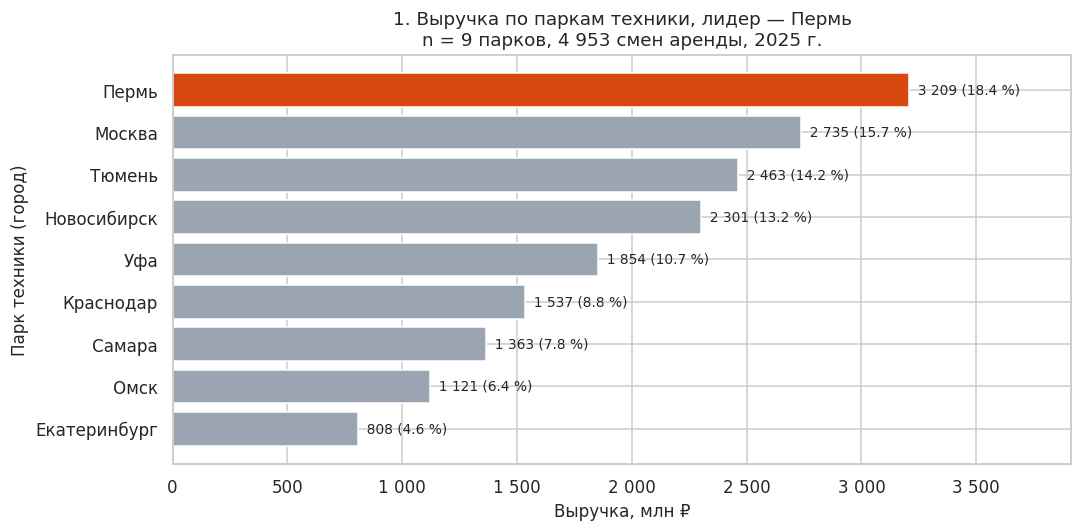

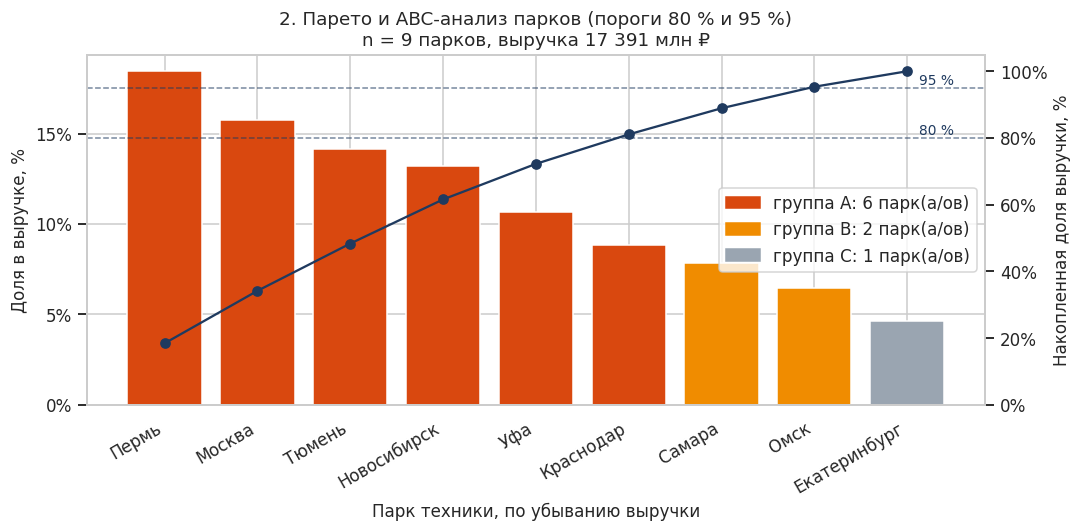

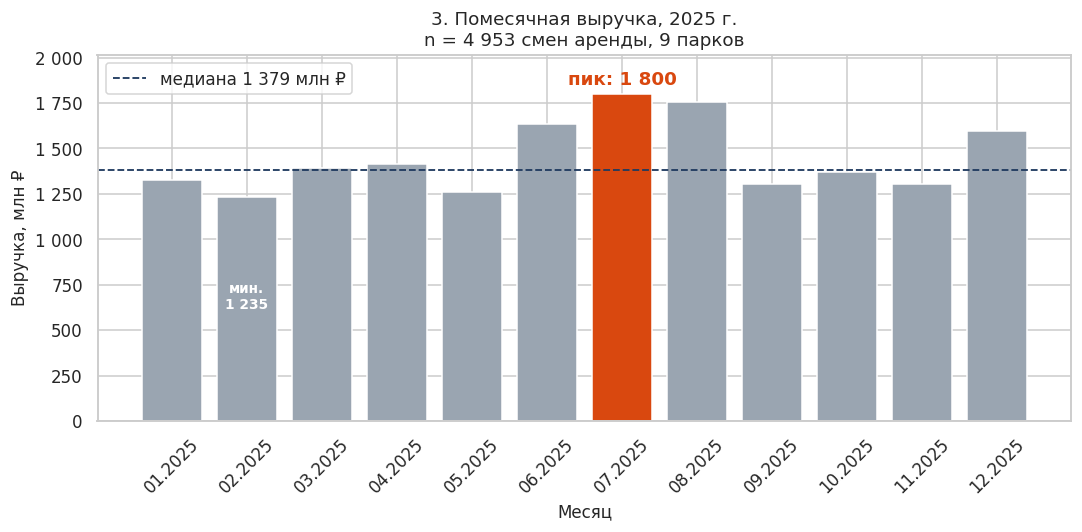

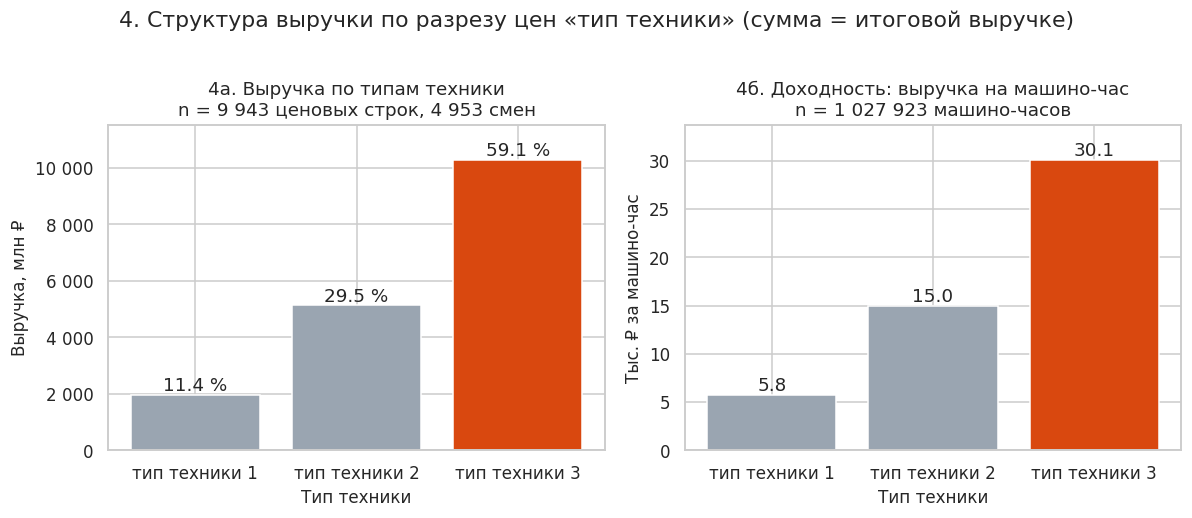

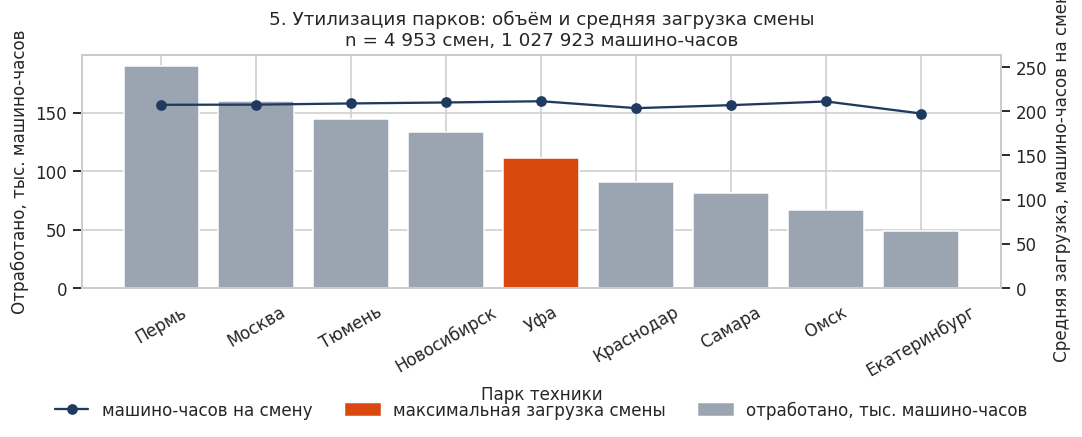

,entity_id,entity_name,смен,машино_часов,выручка,₽ за машино-час,машино-часов на смену,"доля, %","накоплено, %",ABC
0,E001,Парки техники «Пермь»,919,"190,375.00","3,208,539,934.89","16,853.79",207.15,18.45,18.45,A
1,E002,Парки техники «Москва»,773,"160,270.00","2,735,400,161.84","17,067.45",207.34,15.73,34.18,A
2,E003,Парки техники «Тюмень»,693,"144,622.00","2,463,000,081.40","17,030.60",208.69,14.16,48.34,A
3,E004,Парки техники «Новосибирск»,637,"133,636.00","2,301,244,213.50","17,220.24",209.79,13.23,61.57,A
4,E005,Парки техники «Уфа»,525,"110,871.00","1,854,255,181.59","16,724.44",211.18,10.66,72.24,A
5,E006,Парки техники «Краснодар»,448,"91,108.00","1,536,724,799.41","16,867.07",203.37,8.84,81.07,A
6,E007,Парки техники «Самара»,393,"81,259.00","1,362,758,182.93","16,770.55",206.77,7.84,88.91,B
7,E008,Парки техники «Омск»,316,"66,655.00","1,120,702,752.37","16,813.48",210.93,6.44,95.35,B
8,E009,Парки техники «Екатеринбург»,249,"49,127.00","808,125,074.94","16,449.71",197.30,4.65,100.00,C


,price_class,ценовых_строк,машино_часов,выручка,"доля, %",₽ за машино-час
0,тип техники 1,3282,"342,883.83","1,975,011,788.51",11.36,"5,760.00"
1,тип техники 2,3333,"343,191.83","5,135,746,602.64",29.53,"14,964.65"
2,тип техники 3,3328,"341,847.33","10,279,991,991.72",59.11,"30,071.88"


,month,смен,машино_часов,выручка,"к медиане, %"
0,2025-01,427,"80,364.00","1,328,335,399.76",96.29
1,2025-02,386,"73,634.00","1,234,714,862.07",89.51
2,2025-03,408,"79,581.00","1,391,533,332.89",100.88
3,2025-04,427,"82,028.00","1,412,242,074.94",102.38
4,2025-05,392,"71,293.00","1,259,888,775.10",91.33
5,2025-06,406,"98,783.00","1,635,427,335.91",118.56
6,2025-07,431,"104,219.00","1,800,266,917.56",130.51
7,2025-08,422,"103,595.00","1,756,662,571.82",127.35
8,2025-09,374,"72,694.00","1,301,738,873.42",94.37
9,2025-10,424,"79,917.00","1,367,361,790.61",99.12


Витрина сохранена: mart_variant_16.xlsx, mart_events_variant_16.csv и таблицы mart_* в consolidation_variant_16.sqlite

ВЫВОДЫ ДЛЯ ЛПР — вариант 16: Аренда спецтехники (9 парков, 4 953 смен, 17 390.8 млн ₽)

1. Концентрация. В группу A (80 % выручки) входят 6 из 9 парков: Пермь, Москва, Тюмень, Новосибирск, Уфа, Краснодар.
   Лидер — Пермь: 18.4 % выручки; последний — Екатеринбург: 4.6 %.
   Разрыв лидера и аутсайдера — 4.0 раза, и он создан числом смен (919 против 249),
   а не ценой: выручка на машино-час у парков близка (16 450–17 220 ₽).
2. Сезонность. Пик — 07.2025 (1 800 млн ₽), минимум — 02.2025
   (1 235 млн ₽), размах 1.46 раза. Средний месяц июнь–август и декабрь даёт на
   28 % больше выручки, чем остальные месяцы, — за счёт более длинных смен.
3. Доходность типов техники. тип техники 3 даёт 59.1 % выручки при 30 072 ₽/маш.-ч —
   в 5.2 раза дороже, чем тип техники 1 (11.4 % выручки).
4. Качество данных. Наивный JOIN завысил бы выручку в 1.99 раза (+17 281 898 747 ₽).
   В к

In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.
from matplotlib.ticker import FuncFormatter, PercentFormatter, MultipleLocator

BASE, ACCENT, MUTED, LINE = "#9AA5B1", "#D9480F", "#CED4DA", "#1F3A5F"
MLN = 1e6
fmt_mln = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
UNIT = CFG["unit"]

rev = consolidated.dropna(subset=["revenue"])            # события с известной выручкой
TOTAL = rev["revenue"].sum()
N_EV, N_ENT = len(rev), rev["entity_id"].nunique()
short = lambda s: s.replace(CFG["parent"] + " ", "").strip("«»")

# --- Срезы витрины ----------------------------------------------------------------------
by_entity = (rev.groupby(["entity_id", "entity_name"])
             .agg(смен=("event_id", "count"), машино_часов=("volume_units", "sum"), выручка=("revenue", "sum"))
             .reset_index().sort_values("выручка", ascending=False).reset_index(drop=True))
by_entity["₽ за машино-час"] = by_entity["выручка"] / by_entity["машино_часов"]
by_entity["машино-часов на смену"] = by_entity["машино_часов"] / by_entity["смен"]
by_entity["доля, %"] = 100 * by_entity["выручка"] / TOTAL
by_entity["накоплено, %"] = by_entity["доля, %"].cumsum()
by_entity["ABC"] = np.select([by_entity["накоплено, %"].shift(fill_value=0) < 80,
                              by_entity["накоплено, %"].shift(fill_value=0) < 95], ["A", "B"], "C")

by_month = (rev.groupby("month").agg(смен=("event_id", "count"), машино_часов=("volume_units", "sum"),
                                      выручка=("revenue", "sum")).reset_index())

# структура по типу техники без повторного fan-out: вклад ценовой строки = v · pᵢ / nₑ,
# сумма вкладов строк события равна v · p̄ₑ, т. е. ровно выручке события
pr_rows = prices_valid.merge(rev[["event_id", "volume_units", "n_prices"]], on="event_id", how="inner")
pr_rows["revenue_share"] = pr_rows["volume_units"] * pr_rows["unit_price"] / pr_rows["n_prices"]
pr_rows["volume_share"] = pr_rows["volume_units"] / pr_rows["n_prices"]
by_class = (pr_rows.groupby("price_class").agg(ценовых_строк=("price_id", "count"),
                                               машино_часов=("volume_share", "sum"),
                                               выручка=("revenue_share", "sum"))
            .reset_index().sort_values("price_class"))
by_class["доля, %"] = 100 * by_class["выручка"] / TOTAL
by_class["₽ за машино-час"] = by_class["выручка"] / by_class["машино_часов"]

by_asset = (rev.groupby("asset_type").agg(смен=("event_id", "count"), машино_часов=("volume_units", "sum"),
                                         выручка=("revenue", "sum")).reset_index())
by_region = rev.groupby("region", dropna=False)["revenue"].sum()

# --- Контроль сходимости: сумма по любому разрезу = итог -------------------------------
conv = pd.DataFrame([
    {"разрез": "по субъектам (pandas)", "сумма, ₽": by_entity["выручка"].sum()},
    {"разрез": "по месяцам", "сумма, ₽": by_month["выручка"].sum()},
    {"разрез": f"по разрезу цен ({CFG['cls']})", "сумма, ₽": by_class["выручка"].sum()},
    {"разрез": "по полю asset_type (Тип A–D)", "сумма, ₽": by_asset["выручка"].sum()},
    {"разрез": "по регионам (вкл. пропуск региона)", "сумма, ₽": by_region.sum()},
    {"разрез": "итог SQL (шаг 5)", "сумма, ₽": revenue_sql["revenue"].sum()},
])
conv["отклонение от итога, ₽"] = conv["сумма, ₽"] - TOTAL
display(conv)
assert conv["отклонение от итога, ₽"].abs().max() < 1.0, "срез не сходится с итогом — повторный fan-out?"
print(f"Итоговая выручка: {nf(TOTAL, 2)} ₽ — все срезы сходятся (макс. отклонение "
      f"{conv['отклонение от итога, ₽'].abs().max():.4f} ₽, это округление SQL)")

# ---------- График 1. Выручка по субъектам ---------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
colors = [ACCENT if i == 0 else BASE for i in range(len(by_entity))]
bars = ax.barh(by_entity["entity_name"].map(short), by_entity["выручка"] / MLN, color=colors)
ax.invert_yaxis()
for b, s in zip(bars, by_entity["доля, %"]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {b.get_width():,.0f} ({s:.1f} %)".replace(",", " "),
            va="center", fontsize=9)
ax.set_title(f"1. Выручка по паркам техники, лидер — {short(by_entity.loc[0, 'entity_name'])}\n"
             f"n = {N_ENT} парков, {nf(N_EV)} смен аренды, 2025 г.")
ax.set_xlabel("Выручка, млн ₽")
ax.set_ylabel("Парк техники (город)")
ax.xaxis.set_major_formatter(fmt_mln)
ax.set_xlim(0, by_entity["выручка"].max() / MLN * 1.22)
plt.tight_layout(); plt.show()

# ---------- График 2. Парето / ABC -----------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
abc_col = {"A": ACCENT, "B": "#F08C00", "C": BASE}
x = np.arange(len(by_entity))
ax.bar(x, by_entity["доля, %"], color=by_entity["ABC"].map(abc_col))
ax.set_xticks(x, by_entity["entity_name"].map(short), rotation=30, ha="right")
ax.set_ylabel("Доля в выручке, %")
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.yaxis.set_major_locator(MultipleLocator(5))
ax2 = ax.twinx()
ax2.plot(x, by_entity["накоплено, %"], color=LINE, marker="o")
for thr in (80, 95):
    ax2.axhline(thr, ls="--", color=LINE, lw=1, alpha=.6)
    ax2.text(len(x) - .5, thr + 1, f"{thr} %", color=LINE, ha="right", fontsize=9)
ax2.set_ylim(0, 105); ax2.set_ylabel("Накопленная доля выручки, %")
ax2.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax2.grid(False)
abc_cnt = by_entity["ABC"].value_counts().reindex(["A", "B", "C"], fill_value=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=abc_col[k], label=f"группа {k}: {abc_cnt[k]} парк(а/ов)") for k in "ABC"],
          loc="center right")
ax.set_title(f"2. Парето и ABC-анализ парков (пороги 80 % и 95 %)\nn = {N_ENT} парков, выручка {nf(TOTAL / MLN)} млн ₽")
ax.set_xlabel("Парк техники, по убыванию выручки")
plt.tight_layout(); plt.show()

# ---------- График 3. Сезонность -------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
m_lbl = pd.to_datetime(by_month["month"]).dt.strftime("%m.%Y")
peak_i = int(by_month["выручка"].idxmax()); low_i = int(by_month["выручка"].idxmin())
med = by_month["выручка"].median() / MLN
ax.bar(m_lbl, by_month["выручка"] / MLN,
       color=[ACCENT if i == peak_i else BASE for i in range(len(by_month))])
ax.axhline(med, color=LINE, ls="--", lw=1.2, label=f"медиана {med:,.0f} млн ₽".replace(",", " "))
ax.annotate(f"пик: {by_month.loc[peak_i, 'выручка'] / MLN:,.0f}".replace(",", " "),
            (peak_i, by_month.loc[peak_i, "выручка"] / MLN), xytext=(0, 6), textcoords="offset points",
            ha="center", color=ACCENT, fontweight="bold")
ax.text(low_i, by_month.loc[low_i, "выручка"] / MLN / 2,
        f"мин.\n{by_month.loc[low_i, 'выручка'] / MLN:,.0f}".replace(",", " "), ha="center", color="white",
        fontsize=9, fontweight="bold")
ax.set_ylim(0, by_month["выручка"].max() / MLN * 1.12)
ax.set_title(f"3. Помесячная выручка, 2025 г.\nn = {nf(N_EV)} смен аренды, {N_ENT} парков")
ax.set_xlabel("Месяц"); ax.set_ylabel("Выручка, млн ₽")
ax.yaxis.set_major_formatter(fmt_mln)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# ---------- График 4. Структура по типу техники ---------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
lead_c = int(by_class["выручка"].idxmax())
c_colors = [ACCENT if i == lead_c else BASE for i in by_class.index]
axes[0].bar(by_class["price_class"], by_class["выручка"] / MLN, color=c_colors)
for i, (v, sh) in enumerate(zip(by_class["выручка"], by_class["доля, %"])):
    axes[0].text(i, v / MLN, f"{sh:.1f} %", ha="center", va="bottom")
axes[0].set_title(f"4а. Выручка по типам техники\nn = {nf(len(pr_rows))} ценовых строк, {nf(N_EV)} смен")
axes[0].set_xlabel(CFG["cls"].capitalize()); axes[0].set_ylabel("Выручка, млн ₽")
axes[0].yaxis.set_major_formatter(fmt_mln)
axes[0].set_ylim(0, by_class["выручка"].max() / MLN * 1.12)
axes[1].set_ylim(0, by_class["₽ за машино-час"].max() / 1000 * 1.12)
axes[1].bar(by_class["price_class"], by_class["₽ за машино-час"] / 1000, color=c_colors)
for i, v in enumerate(by_class["₽ за машино-час"]):
    axes[1].text(i, v / 1000, f"{v / 1000:,.1f}".replace(",", " "), ha="center", va="bottom")
axes[1].set_title(f"4б. Доходность: выручка на машино-час\nn = {nf(by_class['машино_часов'].sum())} {UNIT}")
axes[1].set_xlabel(CFG["cls"].capitalize()); axes[1].set_ylabel("Тыс. ₽ за машино-час")
fig.suptitle("4. Структура выручки по разрезу цен «тип техники» (сумма = итоговой выручке)", y=1.02)
plt.tight_layout(); plt.show()

# ---------- График 5 (по варианту). Утилизация парка ----------------------------------
fig, ax = plt.subplots(figsize=(10, 4.8))
u = by_entity.sort_values("машино_часов", ascending=False)
ax.bar(u["entity_name"].map(short), u["машино_часов"] / 1000,
       color=[ACCENT if i == u["машино-часов на смену"].idxmax() else BASE for i in u.index])
ax.set_ylabel("Отработано, тыс. машино-часов")
ax.set_xlabel("Парк техники")
ax.tick_params(axis="x", rotation=30)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(u["entity_name"].map(short), u["машино-часов на смену"], color=LINE, marker="o",
         label="машино-часов на смену")
ax2.set_ylabel("Средняя загрузка, машино-часов на смену")
ax2.set_ylim(0, u["машино-часов на смену"].max() * 1.25)
ax2.legend(handles=[ax2.lines[0], Patch(color=ACCENT, label="максимальная загрузка смены"),
                    Patch(color=BASE, label="отработано, тыс. машино-часов")],
           loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=3, frameon=False)
ax.set_title(f"5. Утилизация парков: объём и средняя загрузка смены\nn = {nf(N_EV)} смен, "
             f"{nf(rev['volume_units'].sum())} {UNIT}")
plt.tight_layout(); plt.show()
PLOTS_DONE = True

display(by_entity.round(2))
display(by_class.round(2))
by_month["к медиане, %"] = 100 * by_month["выручка"] / by_month["выручка"].median()
display(by_month.round(2))

# ---------- Витрина: сохраняем в SQLite и в Excel/CSV ---------------------------------
mart_events = consolidated[["event_id", "entity_id", "entity_name", "region", "event_date", "month",
                            "asset_type", "volume_units", "n_prices", "avg_price", "revenue"]].copy()
mart_events["event_date"] = mart_events["event_date"].dt.strftime("%Y-%m-%d")
mart_tables = {"mart_events": mart_events, "mart_entity": by_entity, "mart_month": by_month,
               "mart_class": by_class, "quality_issues": issues_df, "clean_log": clean_log,
               "quarantine_fk": quarantine_fk.astype(str), "quarantine_price": quarantine_price.astype(str)}
for name, frame in mart_tables.items():
    frame.to_sql(name, conn, if_exists="replace", index=False)
conn.execute("DROP VIEW IF EXISTS v_revenue_by_entity")
conn.execute(f"CREATE VIEW v_revenue_by_entity AS {correct_sql.replace('ORDER BY revenue DESC', '')}")
conn.commit()
MART_XLSX = WORK / f"mart_variant_{VARIANT}.xlsx"
with pd.ExcelWriter(MART_XLSX) as xw:
    for name, frame in mart_tables.items():
        frame.to_excel(xw, sheet_name=name[:31], index=False)
mart_events.to_csv(WORK / f"mart_events_variant_{VARIANT}.csv", index=False, encoding="utf-8-sig")
print(f"Витрина сохранена: {MART_XLSX.name}, mart_events_variant_{VARIANT}.csv и таблицы mart_* в {DB_PATH.name}")

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.
a_parks = by_entity[by_entity["ABC"] == "A"]
n_txt_susp = int(issues_df.loc[issues_df["проблема"].str.startswith("ставка строкой"), "строк"].sum())
top, bottom = by_entity.iloc[0], by_entity.iloc[-1]
summer = by_month[by_month["month"].str[-2:].isin(["06", "07", "08", "12"])]["выручка"].mean()
other = by_month[~by_month["month"].str[-2:].isin(["06", "07", "08", "12"])]["выручка"].mean()
peak, low = by_month.loc[peak_i], by_month.loc[low_i]
c3 = by_class.iloc[-1]; c1 = by_class.iloc[0]
q_share = 100 * (len(quarantine_fk) + len(quarantine_price)) / (len(raw_events) + len(raw_prices))
lost_ev = len(events_valid) - len(rev)

conclusions = f"""
ВЫВОДЫ ДЛЯ ЛПР — вариант {VARIANT}: {CFG['domain']} ({N_ENT} парков, {nf(N_EV)} смен, {nf(TOTAL / MLN, 1)} млн ₽)

1. Концентрация. В группу A (80 % выручки) входят {len(a_parks)} из {N_ENT} парков: {', '.join(a_parks['entity_name'].map(short))}.
   Лидер — {short(top['entity_name'])}: {top['доля, %']:.1f} % выручки; последний — {short(bottom['entity_name'])}: {bottom['доля, %']:.1f} %.
   Разрыв лидера и аутсайдера — {top['выручка'] / bottom['выручка']:.1f} раза, и он создан числом смен ({top['смен']} против {bottom['смен']}),
   а не ценой: выручка на машино-час у парков близка ({nf(by_entity['₽ за машино-час'].min())}–{nf(by_entity['₽ за машино-час'].max())} ₽).
2. Сезонность. Пик — {pd.Timestamp(peak['month']).strftime('%m.%Y')} ({nf(peak['выручка'] / MLN)} млн ₽), минимум — {pd.Timestamp(low['month']).strftime('%m.%Y')}
   ({nf(low['выручка'] / MLN)} млн ₽), размах {peak['выручка'] / low['выручка']:.2f} раза. Средний месяц июнь–август и декабрь даёт на
   {100 * (summer / other - 1):.0f} % больше выручки, чем остальные месяцы, — за счёт более длинных смен.
3. Доходность типов техники. {c3['price_class']} даёт {c3['доля, %']:.1f} % выручки при {nf(c3['₽ за машино-час'])} ₽/маш.-ч —
   в {c3['₽ за машино-час'] / c1['₽ за машино-час']:.1f} раза дороже, чем {c1['price_class']} ({c1['доля, %']:.1f} % выручки).
4. Качество данных. Наивный JOIN завысил бы выручку в {overstate:.2f} раза (+{nf(total_naive - total_correct)} ₽).
   В карантин ушло {len(quarantine_fk) + len(quarantine_price)} строк ({q_share:.1f} % событий и цен): {len(q_ev_fk)} смен парка-«сироты» E999,
   их {len(q_pr_fk)} ставок, {int(miss.sum())} ставок без значения и {int(neg.sum())} отрицательных. Ещё {lost_ev} смен не вошли в выручку: {n_null_vol} без объёма (NULL)
   и {int(ev_without_price.sum())} без валидной ставки. {n_txt_susp} ставок, пришедших текстом с «₽», выходят за диапазон ставок своего типа техники.
   Итог — нижняя оценка выручки.

РЕКОМЕНДАЦИИ
R1. Сезонное перераспределение техники. Основание: размах {peak['выручка'] / low['выручка']:.2f}× между пиком и минимумом при близкой ставке.
    Действие: в межсезонье (январь–май, сентябрь–ноябрь) передавать часть единиц из парков группы C в парки группы A
    и проводить ТО именно в эти месяцы. Ожидаемый эффект: +5–8 % машино-часов в пиковые месяцы без закупки техники.
    Проверка: A/B по паркам — помесячные машино-часы на единицу техники до/после, сравнение с прошлым годом.
R2. Приоритет дорогого типа техники в продажах. Основание: {c3['price_class']} — {c3['доля, %']:.0f} % выручки и максимум ₽/маш.-ч.
    Действие: квоты загрузки и бонус менеджерам за смены этого типа в парках A; пакетные предложения «тип 3 + тип 1».
    Ожидаемый эффект: перевод 3 % машино-часов с типа 1 на тип 3 ≈ +{nf(0.03 * by_class['машино_часов'].sum() * (c3['₽ за машино-час'] - c1['₽ за машино-час']) / MLN)} млн ₽ при том же объёме.
    Проверка: ежемесячная доля типа 3 в выручке и ₽/маш.-ч по витрине mart_class.
R3. Контроль качества данных на входе. Основание: {len(q_ev_fk)} смен без парка в справочнике (E999), {int(neg.sum())} отрицательных
    ставок, {int(miss.sum())} пустых ставок и смены без объёма — это неучтённая или спорная выручка.
    Действие: справочник парков как обязательный список в учётной системе, запрет ставки ≤ 0 и пустого объёма на вводе;
    ежедневный отчёт по карантину владельцам источников. Ожидаемый эффект: доля карантина < 0,5 %,
    возврат в отчётность выручки смен E999 (оценка — {nf(q_ev_fk['volume_units'].sum())} маш.-ч).
    Проверка: доля строк в quarantine_* на каждой загрузке; автотест шага 3 падает при превышении порога.

ОГРАНИЧЕНИЯ ДАННЫХ: данные синтетические и охватывают один 2025 год (сезонность не подтверждена на нескольких годах);
цена события — простое среднее ставок (без весов по классам); нет данных о числе единиц техники в парке, поэтому
«утилизация» измерена в машино-часах и машино-часах на смену, а не в % доступного фонда времени; у одного парка не указан регион.
"""
print(conclusions)

In [12]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=conv)

https://docs.google.com/spreadsheets/d/1r527clPVaxNSARTCl1193cE2Vo_vDBArN96XsrOeGgE/edit#gid=0


**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

**Выводы для ЛПР (вариант 16, аренда спецтехники, 2025 г.)**

| | Факт | Решение |
|---|---|---|
| Концентрация | 6 из 9 парков дают 80 % выручки (группа A); лидер Пермь — 18,4 %, Екатеринбург — 4,6 % (C). Разрыв в 4 раза создан числом смен (919 против 249); ставка за машино-час у всех парков почти одинакова (16,4–17,2 тыс. ₽) | Управлять загрузкой, а не ценой |
| Сезонность | Пик — июль (1 800 млн ₽), минимум — февраль (1 235 млн ₽), размах 1,46×; июнь–август и декабрь на 28 % выше остальных месяцев за счёт более длинных смен | Планировать мощности по месяцам, а не по среднегодовому значению |
| Доходность типов | Тип техники 3 — 59 % выручки, 30,1 тыс. ₽/маш.-ч; тип 1 — 11 % выручки, 5,8 тыс. ₽/маш.-ч | Приоритет загрузки дорогого типа |
| Качество данных | Наивный JOIN завышает выручку в 1,99 раза; в карантине 115 строк; 22 смены не вошли в выручку | Контроль на входе |

**Рекомендации**

1. **Сезонное перераспределение техники.** *Основание:* размах 1,46× между пиком и минимумом при одинаковой ставке. *Действие:* в межсезонье переводить часть единиц из парков группы C в парки группы A, а ТО планировать на январь–май и сентябрь–ноябрь. *Ожидаемый эффект:* +5–8 % машино-часов в пиковые месяцы без покупки техники. *Проверка:* помесячные машино-часы на единицу техники до и после, по паркам-участникам и контрольным паркам.
2. **Приоритет типа техники 3 в продажах.** *Основание:* 59 % выручки и в 5,2 раза больше выручки на машино-час, чем у типа 1. *Действие:* квоты загрузки и бонус менеджерам за смены типа 3, пакетные предложения. *Ожидаемый эффект:* перевод 3 % машино-часов с типа 1 на тип 3 даёт ≈ +750 млн ₽ при том же объёме. *Проверка:* ежемесячная доля типа 3 и ₽/маш.-ч в витрине `mart_class`.
3. **Контроль качества на входе.** *Основание:* 25 смен без парка в справочнике (`E999`), 22 отрицательные и 21 пустая ставка, 16 смен без объёма. *Действие:* справочник парков как обязательный список в учётной системе, запрет ставки ≤ 0 и пустого объёма, ежедневный отчёт по карантину. *Ожидаемый эффект:* доля карантина < 0,5 %, возврат в отчётность ≈ 5,6 тыс. машино-часов смен `E999`. *Проверка:* доля строк в `quarantine_*` при каждой загрузке.

**Ограничения данных:** данные синтетические и охватывают один год; цена смены — простое среднее ставок без весов по типам; нет числа единиц техники в парке, поэтому утилизация измерена в машино-часах и машино-часах на смену, а не в процентах доступного фонда; у одного парка не указан регион; 10 текстовых ставок вызывают сомнение в точности. Итоговая выручка — нижняя оценка.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [14]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "pw2-consolidation-makarovavs"   #@param {type:"string"}
BQ_DATASET = "12345"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

Аутентификация в Colab выполнена
Датасет готов: pw2-consolidation-makarovavs.12345 (US)
  загружено entities: 9 строк
  загружено events: 4 975 строк
  загружено prices: 9 977 строк

Оценка объёма чтения: 0.29 МБ (бесплатный лимит — 1 ТБ в месяц)


,entity_name,events_cnt,revenue
0,Парки техники «Пермь»,923,"3,208,539,934.89"
1,Парки техники «Москва»,774,"2,735,400,161.84"
2,Парки техники «Тюмень»,694,"2,463,000,081.40"
3,Парки техники «Новосибирск»,640,"2,301,244,213.50"
4,Парки техники «Уфа»,525,"1,854,255,181.59"
5,Парки техники «Краснодар»,451,"1,536,724,799.41"
6,Парки техники «Самара»,396,"1,362,758,182.93"
7,Парки техники «Омск»,317,"1,120,702,752.37"
8,Парки техники «Екатеринбург»,249,"808,125,074.94"


Максимальное расхождение BigQuery и SQLite: 0.0000


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.

# ===================== ВЫБРАНО НАПРАВЛЕНИЕ A: инкрементальная загрузка (UPSERT) =====================
# Основная база не трогается: догрузка выполняется в копии, чтобы витрина шага 6 осталась воспроизводимой.
INC_DB = WORK / f"consolidation_variant_{VARIANT}_incremental.sqlite"
if INC_DB.exists():
    INC_DB.unlink()
inc = sqlite3.connect(INC_DB)
conn.backup(inc)                                     # полная копия схемы и данных
inc.execute("PRAGMA foreign_keys = ON;")
for t in [x for x in mart_tables] + ["v_revenue_by_entity"]:
    inc.execute(f"DROP {'VIEW' if t.startswith('v_') else 'TABLE'} IF EXISTS {t}")

def generate_next_day(cfg, day="2026-01-01", n_new=60, n_fix=15, seed_shift=1):
    """«Следующий день»: новые смены + корректировки уже загруженных (изменился объём и ставка)
    + одна смена с битым FK — как в реальной ежедневной выгрузке."""
    rng = np.random.default_rng(cfg["seed"] + seed_shift)
    last = int(events_out["event_id"].str[2:].astype(int).max())
    ids = [f"EV{i:06d}" for i in range(last + 1, last + 1 + n_new)]
    ents = rng.choice(entities_out["entity_id"].to_numpy(), n_new)
    new_ev = pd.DataFrame({"event_id": ids, "entity_id": ents,
                           "event_date": [day if i % 4 else pd.Timestamp(day).strftime("%d.%m.%Y")
                                          for i in range(n_new)],              # снова два формата дат
                           "route": "—", "volume_units": [f"{v} " for v in rng.integers(60, 320, n_new)],
                           "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], n_new)})
    new_ev.loc[0, "entity_id"] = "E999"                                       # сирота
    fix = events_out.sample(n_fix, random_state=cfg["seed"]).copy()           # корректировки
    fix["volume_units"] = (fix["volume_units"].fillna(100) + 10).astype(int).astype(str)
    batch_ev = pd.concat([new_ev, fix], ignore_index=True)
    rows, k = [], 1
    for eid in new_ev["event_id"]:
        for _ in range(int(rng.integers(1, 4))):
            kl = f"{cfg['cls']} {int(rng.integers(1, 4))}"
            rows.append({"price_id": f"PRD{day.replace('-', '')}{k:05d}", "event_id": eid,
                         "unit_price": f"{rng.uniform(2500, 9000) * {'1': 1, '2': 2.6, '3': 5.2}[kl[-1]]:,.2f} ₽"
                         .replace(",", " "), "price_class": kl})
            k += 1
    # корректировка ставок исправленных смен: те же price_id, ставка +5 % (UPDATE, а не новая строка)
    fix_pr = prices_out[prices_out["event_id"].isin(fix["event_id"])].copy()
    fix_pr["unit_price"] = (fix_pr["unit_price"] * 1.05).round(2)
    return batch_ev, pd.concat([pd.DataFrame(rows), fix_pr], ignore_index=True)

UPSERT_EVENTS = """
INSERT INTO events (event_id, entity_id, event_date, route, volume_units, asset_type)
VALUES (:event_id, :entity_id, :event_date, :route, :volume_units, :asset_type)
ON CONFLICT(event_id) DO UPDATE SET
    entity_id = excluded.entity_id, event_date = excluded.event_date, route = excluded.route,
    volume_units = excluded.volume_units, asset_type = excluded.asset_type
WHERE events.entity_id IS NOT excluded.entity_id OR events.event_date IS NOT excluded.event_date
   OR events.volume_units IS NOT excluded.volume_units OR events.asset_type IS NOT excluded.asset_type
"""
UPSERT_PRICES = """
INSERT INTO prices (price_id, event_id, unit_price, price_class)
VALUES (:price_id, :event_id, :unit_price, :price_class)
ON CONFLICT(price_id) DO UPDATE SET
    event_id = excluded.event_id, unit_price = excluded.unit_price, price_class = excluded.price_class
WHERE prices.unit_price IS NOT excluded.unit_price OR prices.price_class IS NOT excluded.price_class
"""

def incremental_load(db, batch_ev, batch_pr):
    """Те же правила очистки, что в шаге 4, затем UPSERT в одной транзакции."""
    ev = batch_ev.drop_duplicates("event_id").copy()
    ev["event_date"] = to_date(ev["event_date"]).dt.strftime("%Y-%m-%d")
    ev["volume_units"] = to_number(ev["volume_units"])
    known = {r[0] for r in db.execute("SELECT entity_id FROM entities")}
    q_ev = ev[~ev["entity_id"].isin(known) | ev["event_date"].isna()]
    ev = ev.drop(q_ev.index)
    pr = batch_pr.drop_duplicates("price_id").copy()
    pr["unit_price"] = to_number(pr["unit_price"])
    q_pr = pr[~pr["event_id"].isin(set(ev["event_id"])) | ~(pr["unit_price"] > 0)]
    pr = pr.drop(q_pr.index)
    before = db.total_changes
    with db:                                                    # одна транзакция: всё или ничего
        db.executemany(UPSERT_EVENTS, ev.astype(object).where(ev.notna(), None).to_dict("records"))
        db.executemany(UPSERT_PRICES, pr.astype(object).where(pr.notna(), None).to_dict("records"))
    return {"событий в пакете": len(batch_ev), "цен в пакете": len(batch_pr),
            "в карантин": len(q_ev) + len(q_pr), "изменено строк в БД": db.total_changes - before}

def db_state(db, label):
    r = db.execute("SELECT (SELECT COUNT(*) FROM events), (SELECT COUNT(*) FROM prices), "
                   "(SELECT COUNT(*) - COUNT(DISTINCT event_id) FROM events)").fetchone()
    revenue = pd.read_sql(correct_sql, db)["revenue"].sum()
    return {"состояние": label, "events": r[0], "prices": r[1], "дублей event_id": r[2], "выручка, ₽": revenue}

batch_ev, batch_pr = generate_next_day(CFG)
state = [db_state(inc, "0. исходная база")]
run1 = incremental_load(inc, batch_ev, batch_pr); state.append(db_state(inc, "1. первая догрузка дня"))
run2 = incremental_load(inc, batch_ev, batch_pr); state.append(db_state(inc, "2. повторный запуск того же пакета"))
run3 = incremental_load(inc, batch_ev, batch_pr); state.append(db_state(inc, "3. третий запуск"))
state = pd.DataFrame(state)
display(pd.DataFrame([run1, run2, run3], index=["запуск 1", "запуск 2", "запуск 3"]))
display(state)

# для контраста: «наивная» догрузка простым INSERT без ключа конфликта
try:
    with inc:
        inc.executemany("INSERT INTO events VALUES (:event_id,:entity_id,:event_date,:route,:volume_units,:asset_type)",
                        [dict(event_id=batch_ev.event_id.iloc[1], entity_id="E001", event_date="2026-01-01",
                              route="—", volume_units=100.0, asset_type="Тип A")])
    print("Обычный INSERT принят — PK не защитил бы от дубля!")
except sqlite3.IntegrityError as e:
    print(f"Обычный INSERT повторной строки отклонён ({e}): без UPSERT конвейер падал бы на втором запуске,\n"
          f"а таблица без PK молча получила бы дубли.")

# проверка корректировок: объём исправленной смены обновился, а не задвоился
fixed_id = batch_ev["event_id"].iloc[-1]
print(f"\nСмена {fixed_id}: объём до догрузки "
      f"{events_out.set_index('event_id').loc[fixed_id, 'volume_units']}, после — "
      f"{inc.execute('SELECT volume_units FROM events WHERE event_id=?', (fixed_id,)).fetchone()[0]}, "
      f"строк с этим ключом: {inc.execute('SELECT COUNT(*) FROM events WHERE event_id=?', (fixed_id,)).fetchone()[0]}")

assert state.loc[1:, "дублей event_id"].eq(0).all()
assert state.loc[1, ["events", "prices", "выручка, ₽"]].tolist() == state.loc[3, ["events", "prices", "выручка, ₽"]].tolist()
assert run2["изменено строк в БД"] == 0 and run3["изменено строк в БД"] == 0
print("\n✅ Идемпотентность подтверждена: повторные запуски дают 0 изменённых строк, число строк и выручка "
      "не меняются, дублей ключей нет.")
inc.close()

,событий в пакете,цен в пакете,в карантин,изменено строк в БД
запуск 1,75,162,2,235
запуск 2,75,162,2,0
запуск 3,75,162,2,0


,состояние,events,prices,дублей event_id,"выручка, ₽"
0,0. исходная база,4975,9977,0,"17,390,750,382.87"
1,1. первая догрузка дня,5034,10103,0,"17,611,647,583.45"
2,2. повторный запуск того же пакета,5034,10103,0,"17,611,647,583.45"
3,3. третий запуск,5034,10103,0,"17,611,647,583.45"


Обычный INSERT повторной строки отклонён (UNIQUE constraint failed: events.event_id): без UPSERT конвейер падал бы на втором запуске,
а таблица без PK молча получила бы дубли.

Смена EV001225: объём до догрузки 142.0, после — 152.0, строк с этим ключом: 1

✅ Идемпотентность подтверждена: повторные запуски дают 0 изменённых строк, число строк и выручка не меняются, дублей ключей нет.


**Вывод по заданию со звёздочкой (направление A — инкрементальная загрузка).** Догрузка «следующего дня» (60 новых смен, из них одна с битым ключом `E999`, и 15 корректировок объёма и ставок уже загруженных смен) выполнена через `INSERT … ON CONFLICT DO UPDATE` в одной транзакции и в копии базы, поэтому основная витрина не изменилась. Первая загрузка изменила 235 строк: добавлено 59 смен и 126 ставок, обновлены корректировки, 2 строки ушли в карантин. Второй и третий запуск того же пакета изменили **0 строк**: число строк (5 034 / 10 103) и выручка не изменились, дублей ключей нет — догрузка идемпотентна. Условие `WHERE … IS NOT excluded…` в `DO UPDATE` не даёт перезаписывать неизменившиеся строки. Обычный `INSERT` повторной строки СУБД отклоняет по первичному ключу, а в таблице без PK он молча создал бы дубль.